# Đồ án 1: NHẬN DẠNG CHỮ SỐ VIẾT TAY MNIST - Tái tạo kết quả chính

Môn học: Nhận dạng mẫu (MTH10322)   
Thông tin nhóm:   
| Họ và tên | MSSV |
|---|---|
| Trần Ngọc Các Uyên | 24280030 |
| Lê Minh Phúc Tiên | 24280107 |

Notebook này tập hợp và **kiểm tra lại** các kết quả trong báo cáo, theo hai cách:

1. **Train lại các mô hình nhanh** (Naive Bayes, Logistic Regression, MLP, Random Forest; seed 0, khoảng 3 phút)
   và đối chiếu với bảng đã lưu trong `results/tables/`.
2. **Tính lại accuracy từ xác suất đã lưu** (`results/probs/mnist/*.npy`) so với nhãn thật, cho mọi mô hình,
   kể cả các CNN (train CNN mất hơn 1 giờ trên CPU nên không chạy lại trong notebook).

Các bảng và hình còn lại được sinh bởi các script trong `experiments/`:

| Phần | Lệnh tái tạo |
|---|---|
| 4 bộ phân lớp + CNN, 3 seed | `python -m experiments.run_all --seeds 0 1 2` |
| Siêu tham số, learning curve | `python -m experiments.hyperparams.<mô hình>` |
| Vanishing gradient | `python -m experiments.vanishing_gradient` |
| CNN vs MLP | `python -m experiments.cnn_vs_mlp` |
| Augmentation | `python -m experiments.augmentation_exp` |
| Seed ensemble + TTA | `python -m experiments.seed_ensemble_tta` |
| CNN cải tiến | `python -m experiments.cnn_improved` |

Chạy notebook từ thư mục gốc của repo hoặc từ `notebooks/` (ô đầu tiên tự chuyển thư mục).
Phần nào chưa có kết quả sẽ in ra `(chưa có ...)` thay vì báo lỗi.

In [35]:
import os
import sys

if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
sys.path.insert(0, os.getcwd())

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display

from src.data import load_dataset
from src.utils import load_probs

pd.set_option("display.precision", 4)
pd.set_option("display.width", 160)

RETRAIN = True  # False: bỏ qua phần train lại 4 bộ phân lớp (chỉ đọc kết quả đã lưu)
TABLES, FIGURES = "results/tables", "results/figures"


def table(name):
    path = f"{TABLES}/{name}.csv"
    if not os.path.exists(path):
        print(f"(chưa có {path})")
        return None
    return pd.read_csv(path)


def figure(name, width=900):
    path = f"{FIGURES}/{name}.png"
    if os.path.exists(path):
        display(Image(filename=path, width=width))
    else:
        print(f"(chưa có {path})")


def probs(model, split, dataset="mnist"):
    try:
        return load_probs(dataset, model, split)
    except FileNotFoundError:
        return None


def acc(P, y):
    return float(np.mean(np.asarray(P).argmax(axis=1) == y))


def pct(x):
    return f"{100 * x:.2f}%"

## 1. Dữ liệu

MNIST: 60.000 ảnh train + 10.000 ảnh test, ảnh xám 28×28, 10 lớp (chữ số 0–9).
Tập train gốc được chia cố định (seed 42) thành **50.000 train / 10.000 validation**; tập test gốc giữ nguyên.
Mọi lựa chọn (siêu tham số, số epoch, cấu hình) đều dựa trên **validation**; test chỉ dùng cho số liệu cuối.
Ảnh được chuẩn hóa về [0, 1] và trải phẳng thành vector 784 chiều; CNN tự đưa lại về 1×28×28.

train: X (50000, 784) float32, giá trị [0.0, 1.0], y (50000,)
val  : X (10000, 784) float32, giá trị [0.0, 1.0], y (10000,)
test : X (10000, 784) float32, giá trị [0.0, 1.0], y (10000,)


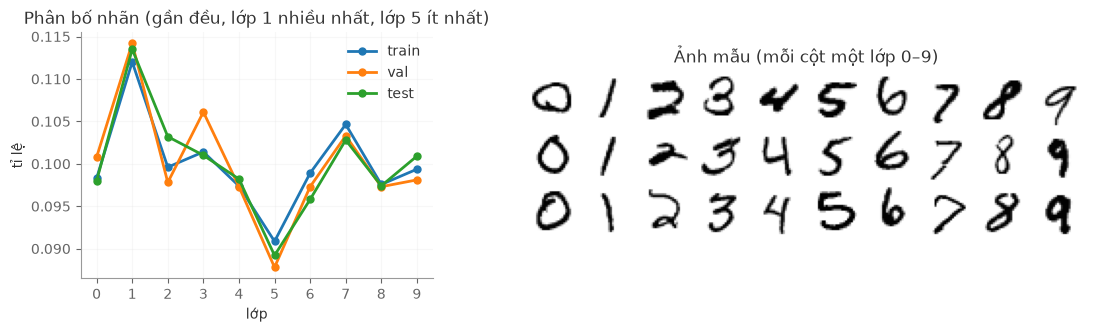

In [36]:
d = load_dataset("mnist")
for split in ("train", "val", "test"):
    X, y = d[f"X_{split}"], d[f"y_{split}"]
    print(f"{split:5s}: X {X.shape} {X.dtype}, giá trị [{X.min():.1f}, {X.max():.1f}], y {y.shape}")

fig, axes = plt.subplots(1, 2, figsize=(13, 3.2), gridspec_kw={"width_ratios": [1, 1.6]})
for split in ("train", "val", "test"):
    counts = np.bincount(d[f"y_{split}"], minlength=10)
    axes[0].plot(range(10), counts / counts.sum(), marker="o", label=split)
axes[0].set_xticks(range(10))
axes[0].set_xlabel("lớp")
axes[0].set_ylabel("tỉ lệ")
axes[0].set_title("Phân bố nhãn (gần đều, lớp 1 nhiều nhất, lớp 5 ít nhất)")
axes[0].legend()
axes[0].grid(alpha=0.3)

# 3 ảnh mẫu cho mỗi lớp
grid = np.ones((3 * 29, 10 * 29))
for c in range(10):
    idx = np.flatnonzero(d["y_train"] == c)[:3]
    for r, i in enumerate(idx):
        grid[r * 29 : r * 29 + 28, c * 29 : c * 29 + 28] = 1 - d["X_train"][i].reshape(28, 28)
axes[1].imshow(grid, cmap="gray")
axes[1].set_axis_off()
axes[1].set_title("Ảnh mẫu (mỗi cột một lớp 0–9)")
plt.show()

## 2. Bốn bộ phân lớp bắt buộc

| Mô hình | Cài đặt (tự viết bằng NumPy, `src/models/`) | Cấu hình cuối (chọn theo validation) |
|---|---|---|
| Gaussian Naive Bayes | ước lượng trung bình, phương sai theo lớp; log-likelihood | `var_smoothing` 0.05 |
| Bernoulli Naive Bayes | nhị phân hóa pixel; làm trơn Laplace | `alpha` 0.01, `binarize` 0.1 |
| Logistic Regression (softmax) | gradient descent theo mini-batch | lr 0.1, 20 epoch |
| MLP | feedforward + backprop tự viết, ReLU, momentum | (256, 128), lr 0.05, momentum 0.9, 20 epoch |
| Random Forest | cây quyết định tự viết, bootstrap, √D đặc trưng, 16 ngưỡng | 100 cây, độ sâu 24 |

scikit-learn chỉ dùng để đối chiếu (`tests/test_against_sklearn.py`).
Ô dưới train lại từng mô hình với seed 0 (cùng hàm `run_model` của `experiments/run_all.py`)
và so với kết quả đã lưu trong `mnist_summary.csv`.

In [37]:
saved = table("mnist_summary")
FAST_MODELS = [
    "naive_bayes",
    "bernoulli_naive_bayes",
    "logistic_regression",
    "mlp",
    "random_forest",
]

if RETRAIN:
    from experiments.run_all import run_model

    rows = []
    for name in FAST_MODELS:
        out = {r["split"]: r for r in run_model(name, d, "mnist", seed=0, save_outputs=False)}
        s = saved[(saved["model"] == name) & (saved["seed"].fillna(0) == 0)].set_index("split")
        rows.append(
            {
                "mô hình": name,
                "val (chạy lại)": out["val"]["accuracy"],
                "val (đã lưu)": s.loc["val", "accuracy"],
                "test (chạy lại)": out["test"]["accuracy"],
                "test (đã lưu)": s.loc["test", "accuracy"],
                "fit (s)": out["test"]["fit_time_s"],
            }
        )
    check = pd.DataFrame(rows)
    check["chênh lệch test"] = check["test (chạy lại)"] - check["test (đã lưu)"]
    display(check)
    print("Chênh lệch cỡ 0,0005 là do khác máy (làm tròn số thực); thời gian phụ thuộc máy.")

Xong naive_bayes (seed None): test acc = 0.8145
Xong bernoulli_naive_bayes (seed None): test acc = 0.8451
Xong logistic_regression (seed 0): test acc = 0.9225
Xong mlp (seed 0): test acc = 0.9831
Xong random_forest (seed 0): test acc = 0.9674


,mô hình,val (chạy lại),val (đã lưu),test (chạy lại),test (đã lưu),fit (s),chênh lệch test
0,naive_bayes,0.7991,0.7991,0.8145,0.8145,1.0117,0.0
1,bernoulli_naive_bayes,0.8352,0.8352,0.8451,0.8451,0.3551,0.0
2,logistic_regression,0.9175,0.9175,0.9225,0.9225,7.0177,0.0
3,mlp,0.9816,0.9816,0.9831,0.9831,33.0977,0.0
4,random_forest,0.9666,0.9666,0.9674,0.9674,168.5791,0.0


Chênh lệch cỡ 0,0005 là do khác máy (làm tròn số thực); thời gian phụ thuộc máy.


Kết quả cuối trên **test**, trung bình ± độ lệch chuẩn theo seed (các mô hình có yếu tố ngẫu nhiên chạy 3 seed;
Naive Bayes không có yếu tố ngẫu nhiên nên chỉ 1 lần):

In [38]:
agg = table("mnist_summary_agg")
if agg is not None:
    t = agg[agg["split"] == "test"].copy()
    tr = agg[agg["split"] == "train"].set_index("model")["accuracy_mean"]
    t["train acc"] = t["model"].map(tr)
    t["test acc"] = [
        pct(m) + ("" if pd.isna(s) else f" ± {100 * s:.2f}%")
        for m, s in zip(t["accuracy_mean"], t["accuracy_std"])
    ]
    t = t.sort_values("accuracy_mean")
    display(
        t[
            [
                "model",
                "n_seeds",
                "test acc",
                "f1_mean",
                "train acc",
                "fit_time_s_mean",
                "predict_time_s_mean",
            ]
        ]
        .rename(
            columns={
                "f1_mean": "F1 (macro)",
                "fit_time_s_mean": "fit (s)",
                "predict_time_s_mean": "predict test (s)",
            }
        )
        .reset_index(drop=True)
    )

,model,n_seeds,test acc,F1 (macro),train acc,fit (s),predict test (s)
0,naive_bayes,1,81.45%,0.8128,0.8026,0.8941,0.0702
1,bernoulli_naive_bayes,1,84.51%,0.8432,0.8345,0.3972,0.0574
2,logistic_regression,3,92.22% ± 0.12%,0.9211,0.9251,3.8092,0.0053
3,random_forest,3,96.74% ± 0.01%,0.9672,0.9988,18.1740,0.6092
4,mlp,3,98.25% ± 0.10%,0.9824,1.0000,23.4293,0.0353
5,cnn,3,99.02% ± 0.18%,0.9901,0.9968,141.5552,1.1610


## 3. Ảnh hưởng của siêu tham số

Mỗi siêu tham số được quét trên validation (script trong `experiments/hyperparams/`).
Một lưu ý dùng xuyên suốt: **đổi seed làm accuracy dao động khoảng ±0,1–0,2%**, nên chênh lệch nhỏ hơn mức đó là nhiễu.

### 3.1 Naive Bayes

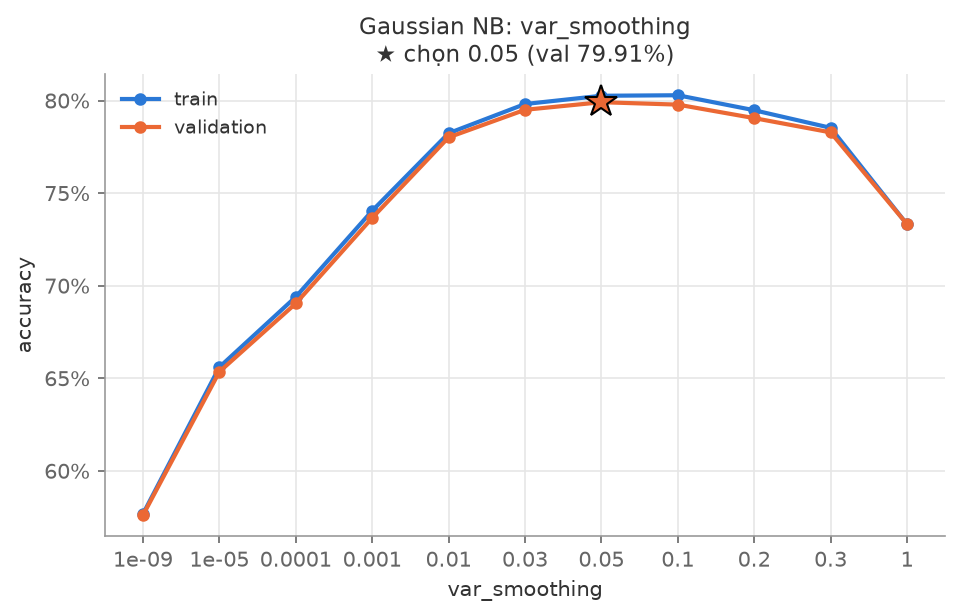

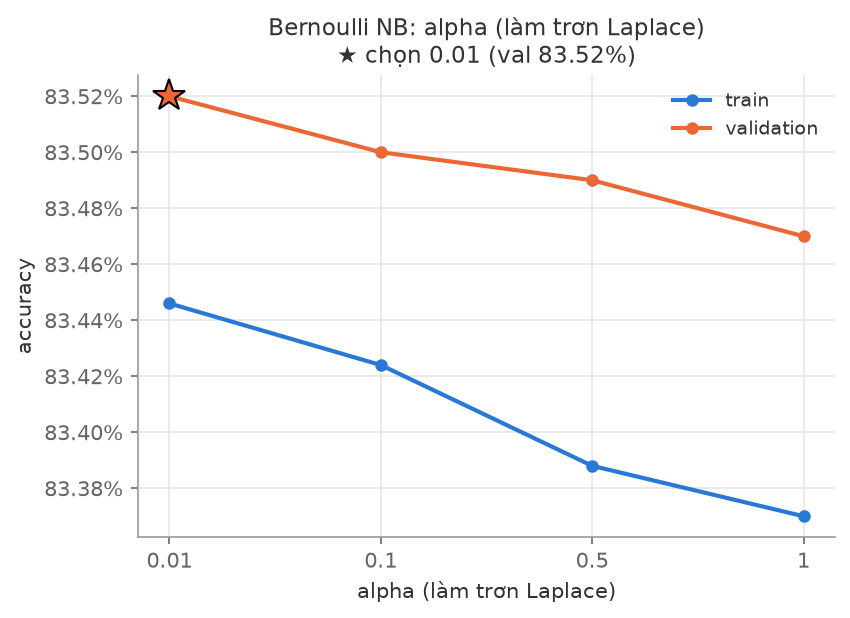

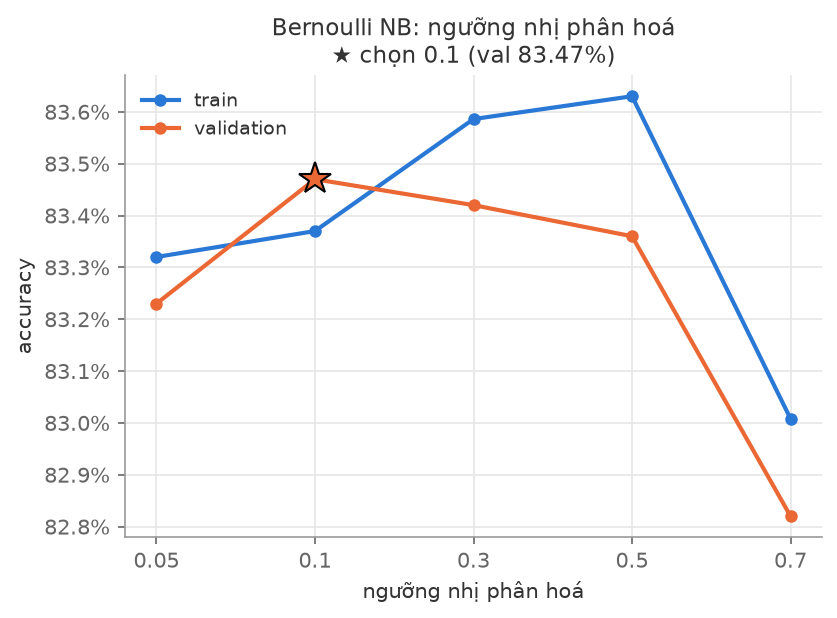

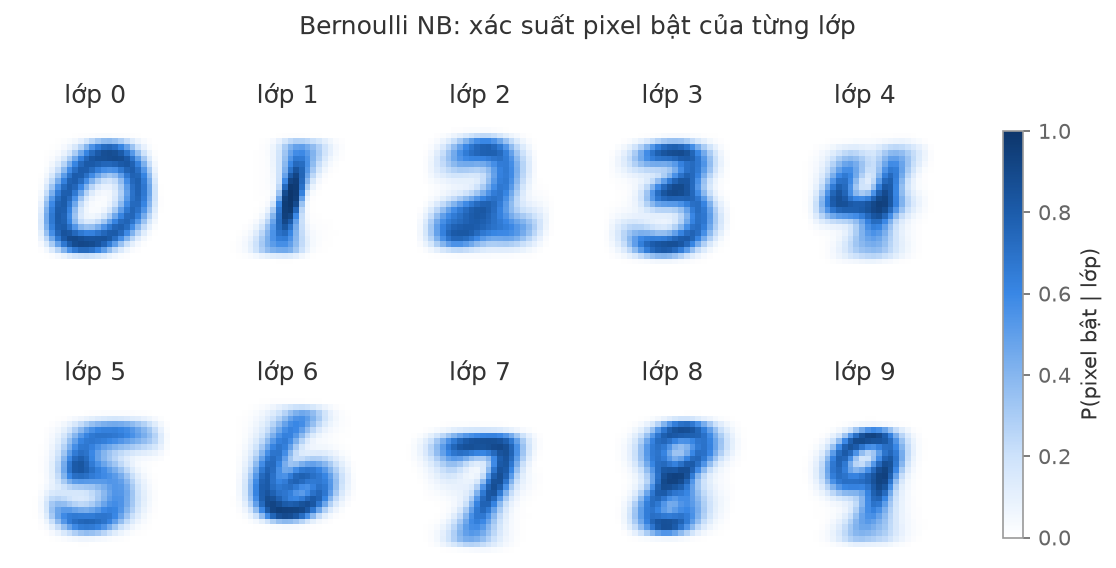

,model,params,val_accuracy,test_accuracy,test_precision,test_recall,test_f1,fit_time_s,test_predict_time_s
0,naive_bayes,var_smoothing=0.05,0.7991,0.8145,0.830,0.8109,0.8128,0.2592,0.0188
1,bernoulli_naive_bayes,"alpha=0.01, binarize=0.1",0.8352,0.8451,0.846,0.8425,0.8432,0.1161,0.0135


In [39]:
for name in [
    "hyperparam_naive_bayes_var_smoothing",
    "hyperparam_bernoulli_naive_bayes_alpha",
    "hyperparam_bernoulli_naive_bayes_binarize",
    "mnist_bernoulli_naive_bayes_pixel_probs",
]:
    figure(name, width=700)
display(table("mnist_naive_bayes_variants"))

Naive Bayes giả định các pixel độc lập khi biết lớp, điều này sai với ảnh (pixel kề nhau tương quan mạnh),
nên accuracy chỉ quanh 81-85%. Bernoulli NB hợp với ảnh gần nhị phân hơn Gaussian NB.

### 3.2 Logistic Regression

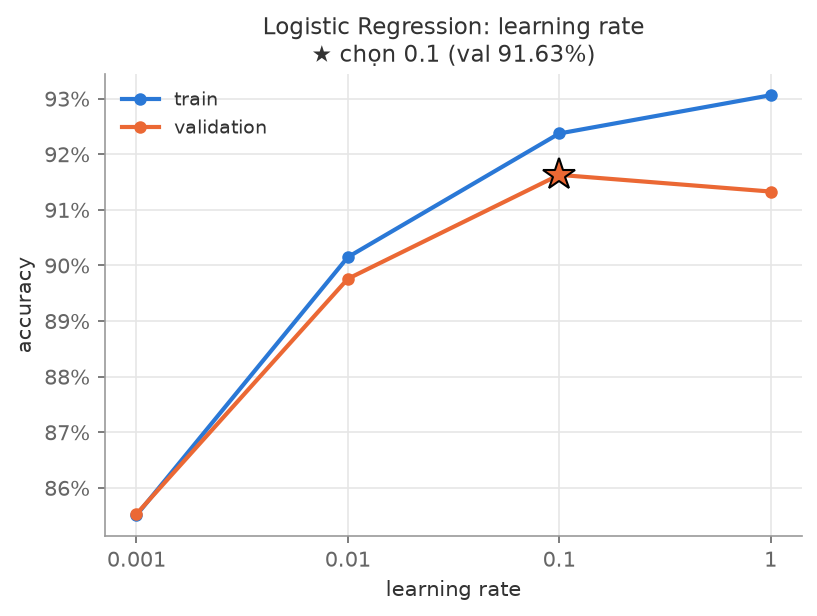

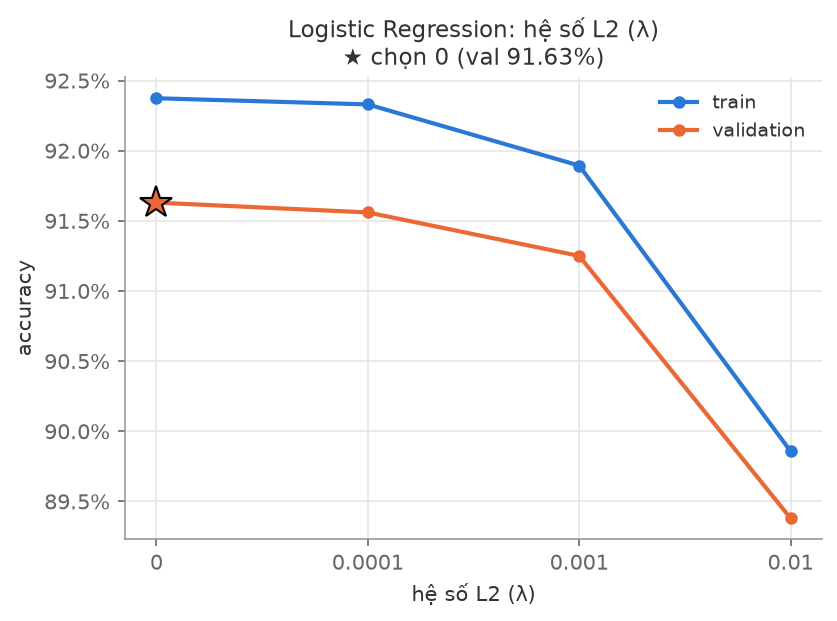

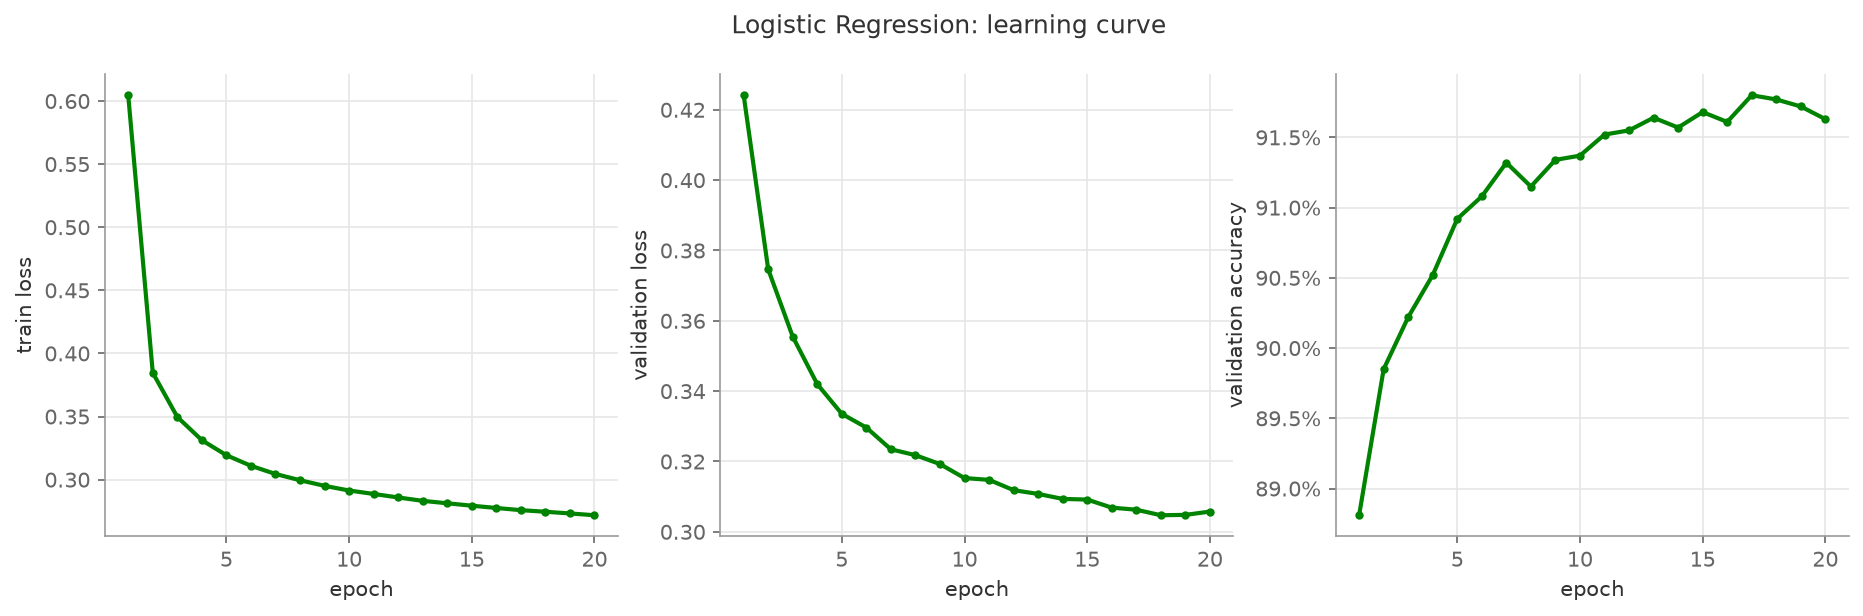

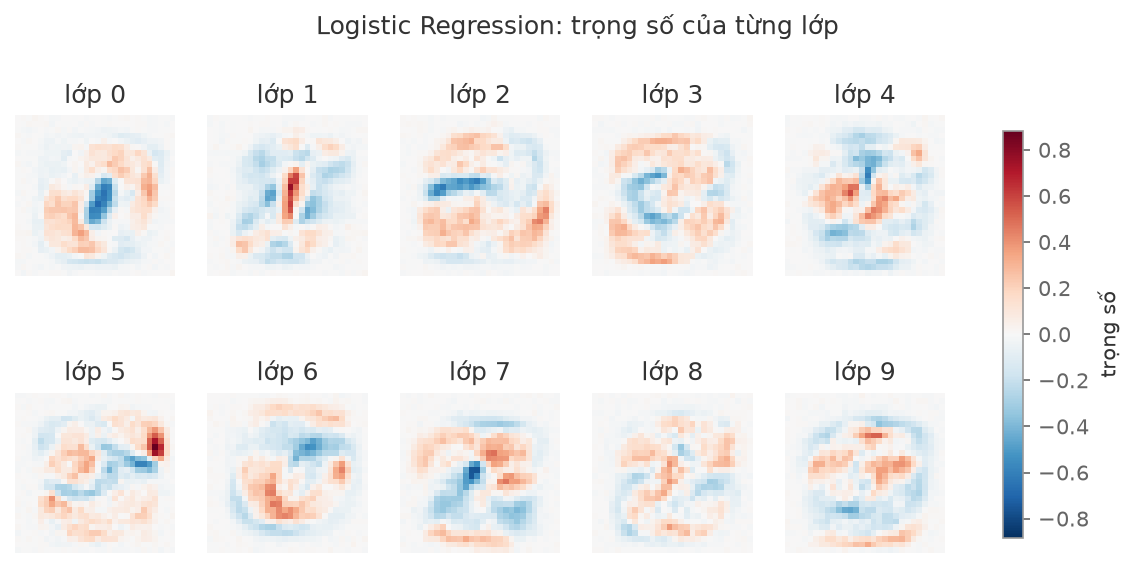

In [40]:
for name in [
    "hyperparam_logistic_regression_lr",
    "hyperparam_logistic_regression_l2",
    "learning_curve_logistic_regression",
    "logistic_regression_weights",
]:
    figure(name, width=700)

Logistic Regression là mô hình tuyến tính nên **thiếu khớp** (train ≈ test ≈ 92%): L2 chỉ làm giảm accuracy.
Ảnh trọng số cho thấy mỗi lớp học một "khuôn" chữ số.

### 3.3 MLP

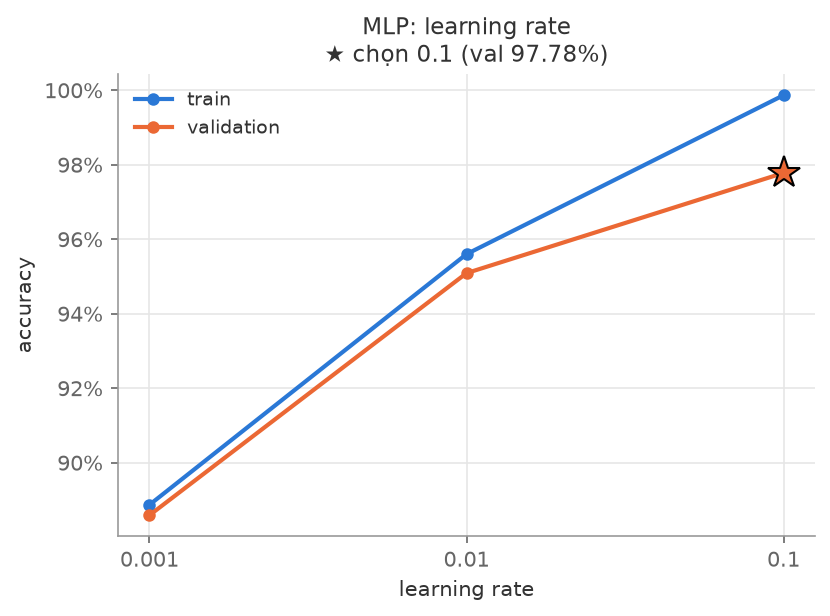

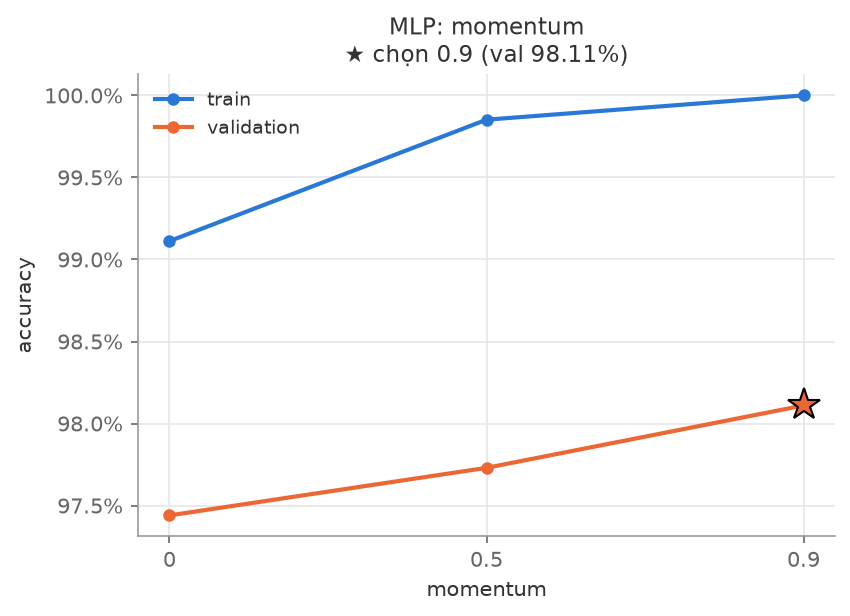

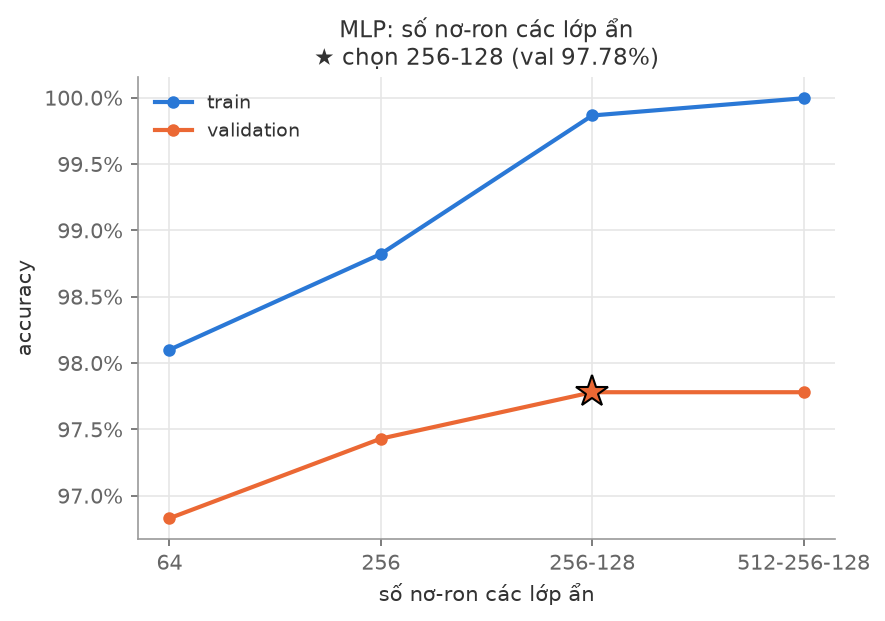

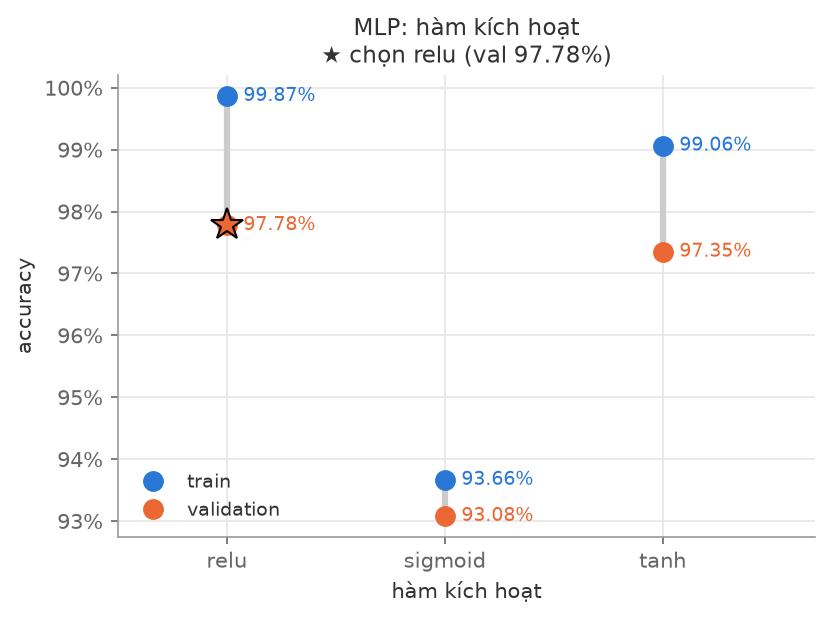

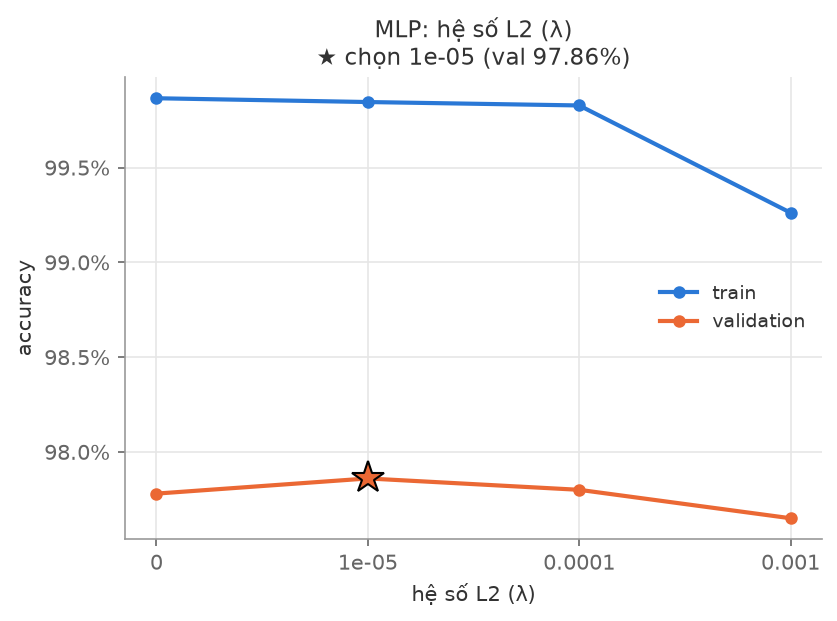

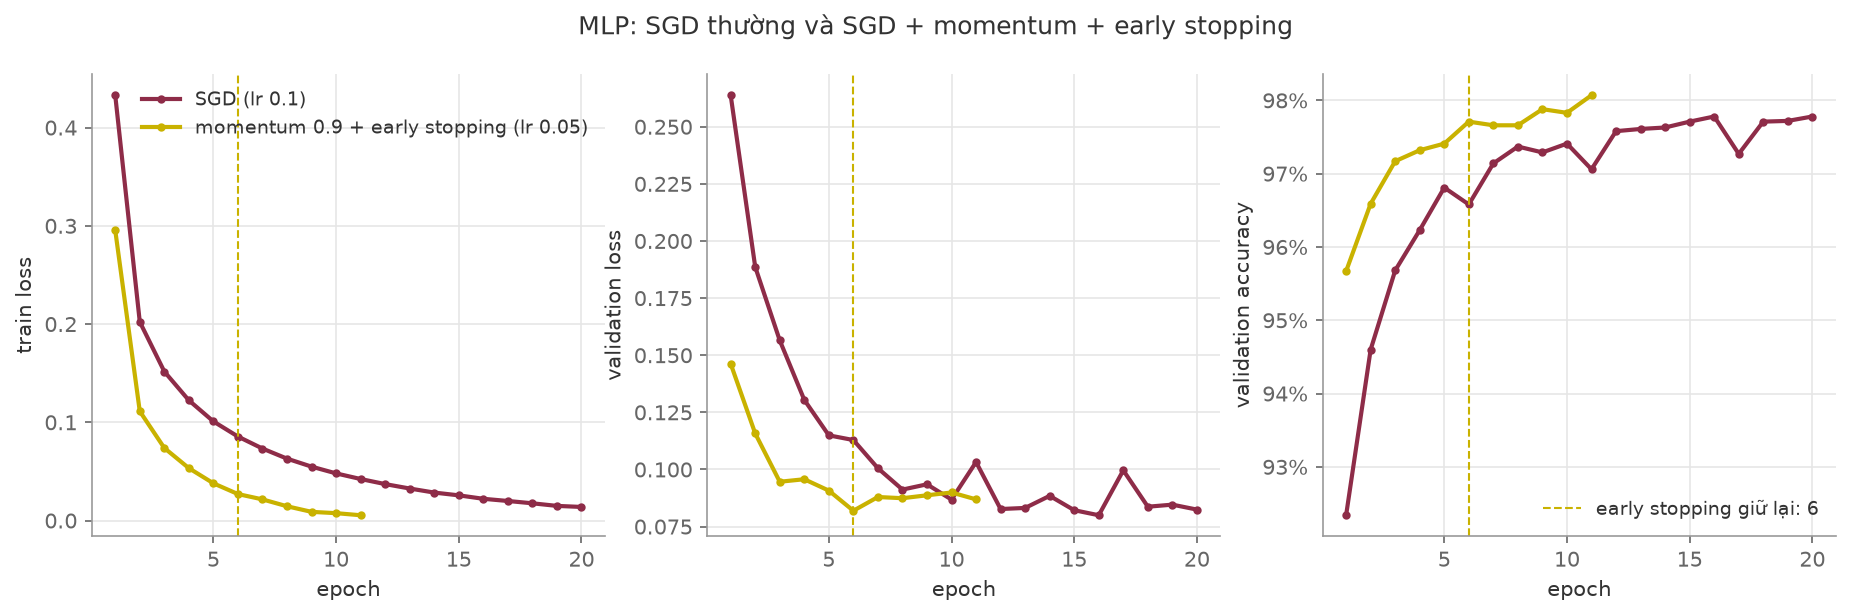

,config,epochs_run,kept_epoch,train_acc,val_acc,fit_time_s
0,SGD (lr 0.1),20,20,0.9987,0.9778,21.6525
1,momentum 0.9 + early stopping (lr 0.05),11,6,0.9963,0.9771,12.1736


In [41]:
for name in [
    "hyperparam_mlp_lr",
    "hyperparam_mlp_momentum",
    "hyperparam_mlp_hidden_sizes",
    "hyperparam_mlp_activation",
    "hyperparam_mlp_l2",
    "learning_curve_mlp",
]:
    figure(name, width=700)
display(table("learning_curve_mlp_summary"))

- MLP **overfit** (train 100%, test 98,25%), ngược với Logistic Regression.
- Momentum giúp thật (+0,34% val); L2 chỉ +0,08%, trong mức nhiễu.
- Early stopping theo val loss dừng quá sớm: val loss tăng lại do mạng **tự tin quá mức** trên một ít ảnh sai,
  trong khi val accuracy vẫn tăng → cấu hình cuối không dùng early stopping, chạy cố định 20 epoch
  (val accuracy phẳng từ khoảng epoch 13).

### 3.4 Vanishing gradient

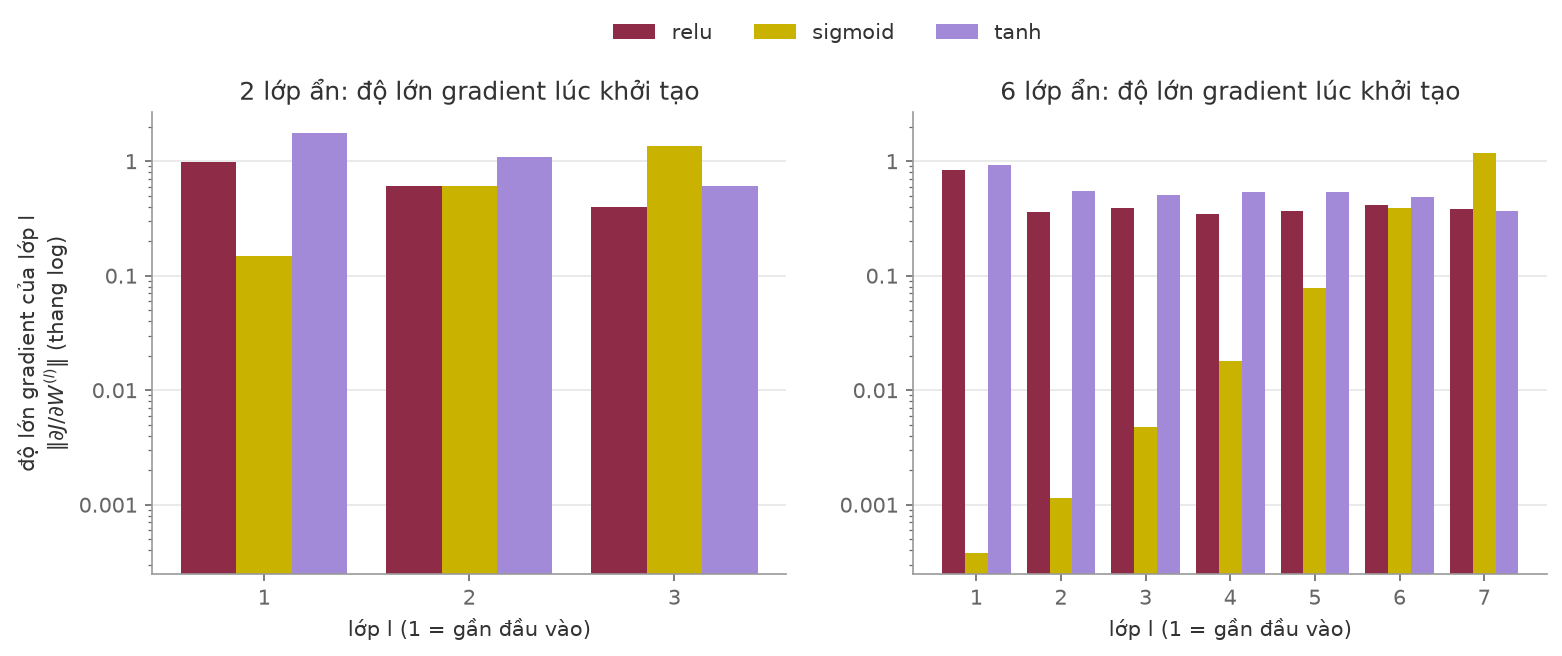

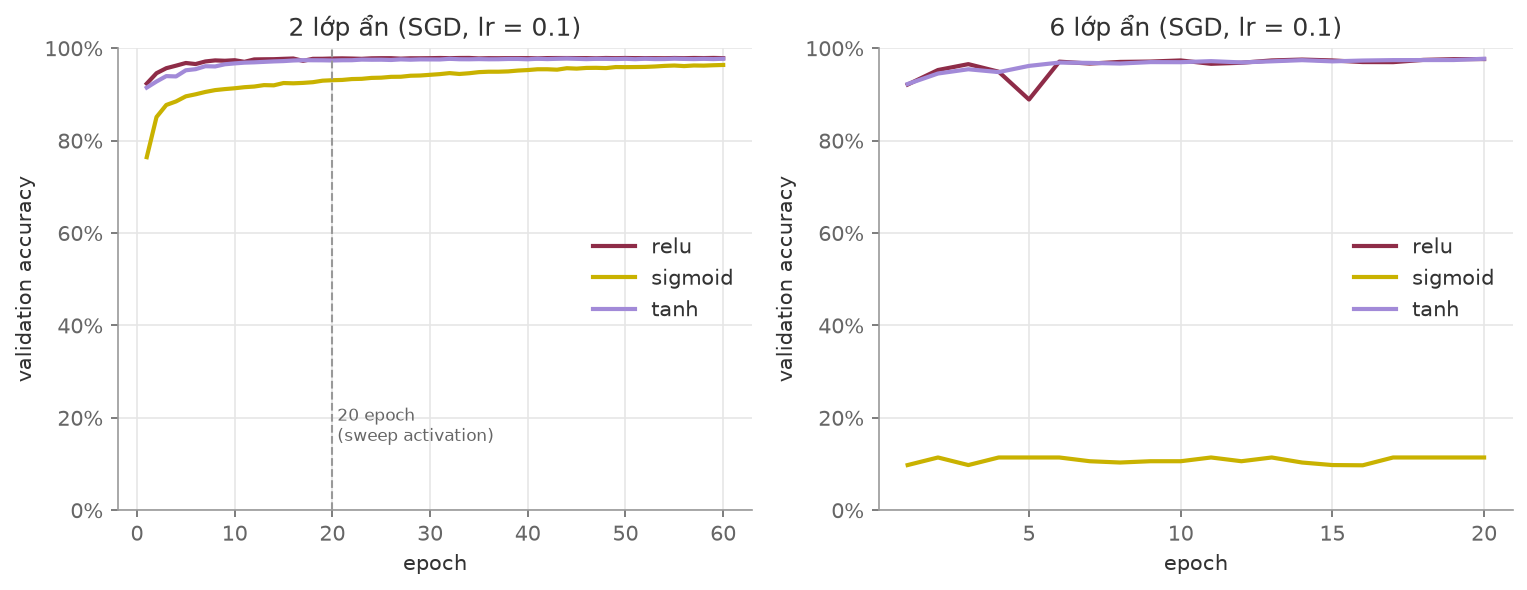

In [42]:
figure("vanishing_gradient_grad_norms", width=750)
figure("vanishing_gradient_curves", width=750)

Với 2 lớp ẩn, sigmoid chỉ hội tụ chậm (gradient lớp đầu nhỏ khoảng 9 lần so với lớp cuối).
Vanishing gradient thật chỉ xuất hiện ở mạng 6 lớp ẩn: gradient lớp đầu nhỏ khoảng 3.000 lần, val accuracy 11% (đoán mò).
ReLU không gặp vấn đề này.

### 3.5 Random Forest

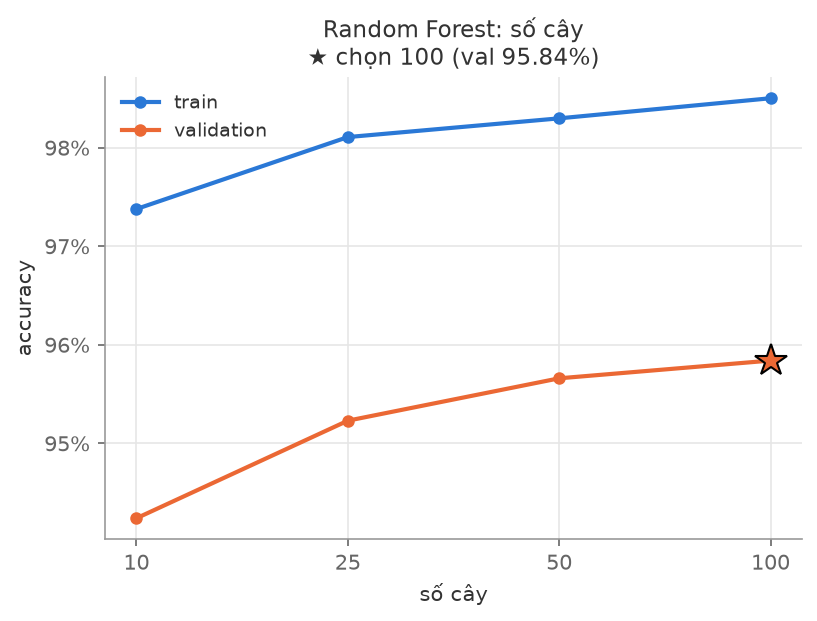

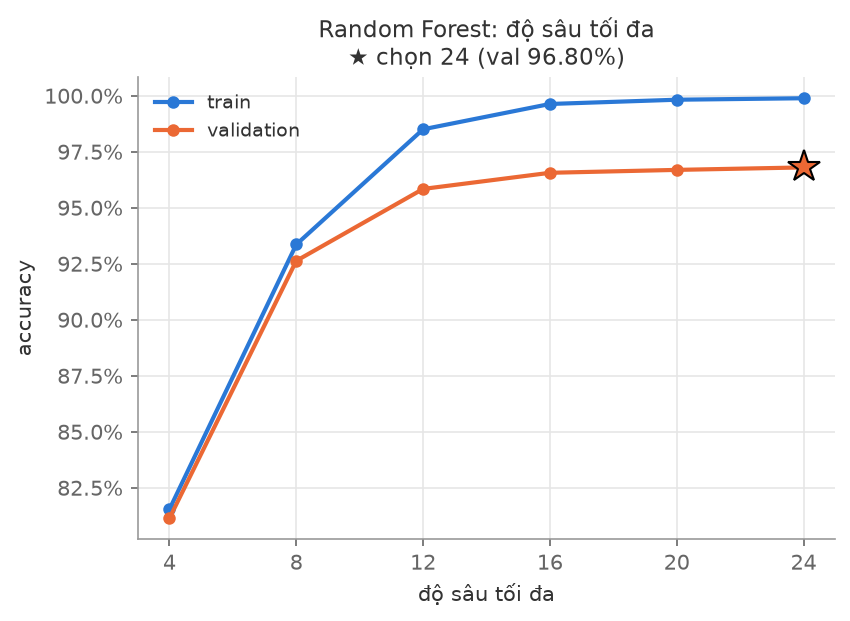

,n_trees,max_depth,max_thresholds,seed,n_jobs,train_size,val_accuracy,test_accuracy,test_precision,test_recall,test_f1,fit_time_s,test_predict_time_s
0,100,24,16,42,-1,50000,0.968,0.9669,0.9667,0.9667,0.9667,17.9449,0.628


In [43]:
for name in ["hyperparam_random_forest_n_trees", "hyperparam_random_forest_max_depth"]:
    figure(name, width=700)
display(table("mnist_random_forest_best"))

## 4. So sánh tổng hợp

Accuracy theo từng lớp, tính từ ma trận nhầm lẫn trên test (seed 0):

,naive_bayes,bernoulli_naive_bayes,logistic_regression,random_forest,mlp,cnn
lớp,,,,,,
0,92.24%,90.82%,97.45%,98.78%,99.29%,99.69%
1,96.39%,95.15%,97.97%,98.94%,99.30%,99.38%
2,75.68%,82.27%,89.83%,96.51%,98.26%,99.52%
3,79.50%,83.96%,90.20%,96.14%,98.51%,99.21%
4,65.07%,82.18%,93.79%,97.05%,98.07%,99.59%
5,64.24%,71.64%,86.32%,96.08%,97.65%,99.10%
6,90.71%,89.46%,95.72%,97.39%,98.33%,98.43%
7,81.23%,84.73%,91.54%,96.11%,97.86%,99.12%
8,76.39%,78.13%,89.22%,95.38%,98.05%,99.08%


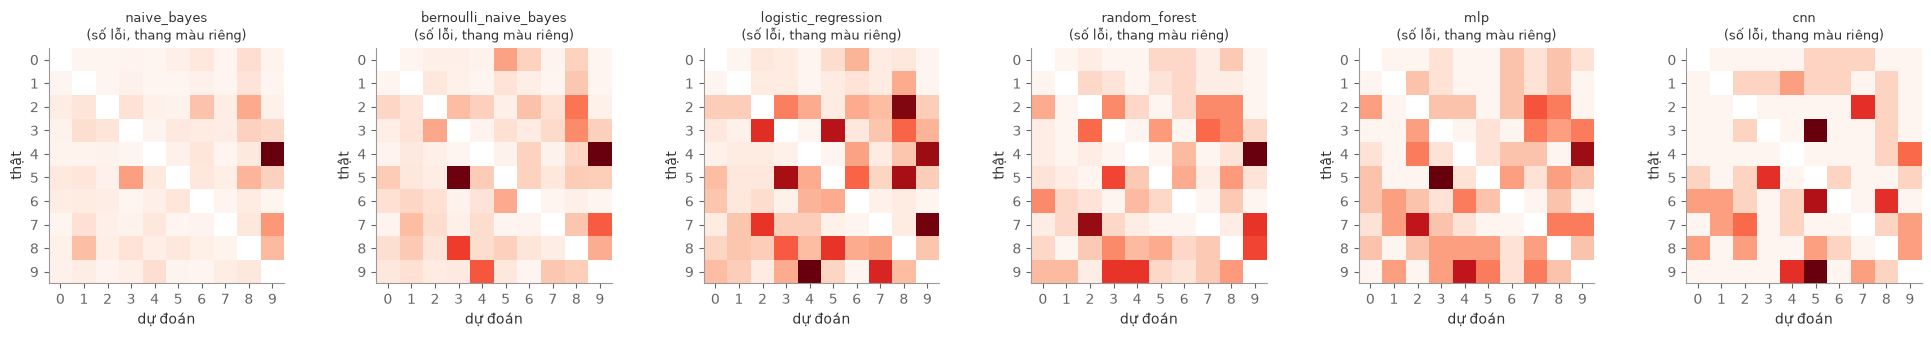

naive_bayes            nhầm nhiều nhất: 4→9 (279), 7→9 (100), 5→3 (93), 2→8 (85)
bernoulli_naive_bayes  nhầm nhiều nhất: 4→9 (119), 5→3 (117), 8→3 (74), 9→4 (66)
logistic_regression    nhầm nhiều nhất: 9→4 (37), 7→9 (36), 2→8 (35), 4→9 (33)
random_forest          nhầm nhiều nhất: 4→9 (20), 7→2 (18), 9→4 (13), 9→3 (13)
mlp                    nhầm nhiều nhất: 5→3 (9), 4→9 (8), 7→2 (7), 9→4 (7)
cnn                    nhầm nhiều nhất: 9→5 (6), 3→5 (6), 6→5 (5), 9→4 (4)


In [44]:
names = [
    "naive_bayes",
    "bernoulli_naive_bayes",
    "logistic_regression",
    "random_forest",
    "mlp",
    "cnn",
]
cms = {n: table(f"mnist_{n}_confusion") for n in names}
cms = {n: c.to_numpy() for n, c in cms.items() if c is not None}
per_class = pd.DataFrame({n: np.diag(c) / c.sum(axis=1) for n, c in cms.items()})
per_class.index.name = "lớp"
display(per_class.style.format("{:.2%}").background_gradient(axis=0, cmap="RdYlGn"))

fig, axes = plt.subplots(1, len(cms), figsize=(3.3 * len(cms), 3.2))
for ax, (n, c) in zip(np.atleast_1d(axes), cms.items()):
    off = c.astype(float)
    np.fill_diagonal(off, np.nan)
    im = ax.imshow(off, cmap="Reds")
    ax.set_title(f"{n}\n(số lỗi, thang màu riêng)", fontsize=9)
    ax.set_xticks(range(10))
    ax.set_yticks(range(10))
    ax.set_xlabel("dự đoán")
    ax.set_ylabel("thật")
plt.tight_layout()
plt.show()

for n, c in cms.items():
    off = c.copy()
    np.fill_diagonal(off, 0)
    top = np.dstack(np.unravel_index(np.argsort(off, axis=None)[::-1][:4], off.shape))[0]
    print(f"{n:22s} nhầm nhiều nhất:", ", ".join(f"{a}→{b} ({off[a, b]})" for a, b in top))

**Vì sao mô hình này tốt, mô hình kia không:**

- **Naive Bayes (81–85%)**: giả định độc lập giữa các pixel quá sai với ảnh.
- **Logistic Regression (92%)**: ranh giới tuyến tính trên pixel thô không đủ tách các chữ số viết khác nhau (thiếu khớp).
- **Random Forest (96,75%)**: phi tuyến, mạnh trên đặc trưng dạng bảng, nhưng mỗi lần chia chỉ xét một pixel ở vị trí cố định.
- **MLP (98,25%)**: học đặc trưng phi tuyến, nhưng coi mỗi pixel là một đặc trưng ở vị trí cố định nên không biết pixel nào kề nhau.
- **CNN (99,0%)**: bộ lọc cục bộ dùng chung ở mọi vị trí → tận dụng cấu trúc không gian, bền với dịch chuyển nhỏ (mục 5).

Lớp 5 khó với hầu hết mô hình cũ; các cặp hay nhầm: 4↔9, 5→3, 7→2, 2→8.

### 4.1 Lỗi của CNN

Ảnh test mà CNN (seed 0) sai với độ tin cậy cao nhất (tương ứng Hình 9 trong báo cáo):

CNN (seed 0) sai 81 ảnh. Độ tin cậy vào nhãn sai: trung vị 79%; 14 ảnh trên 95%, 4 ảnh từ 50% trở xuống.


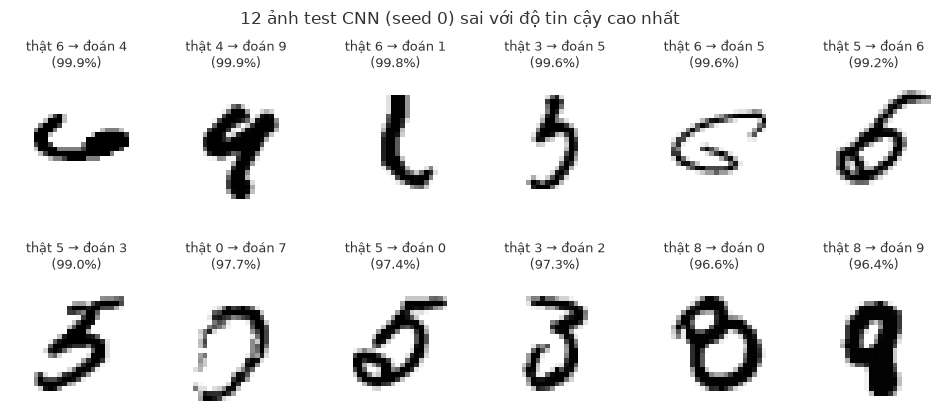

In [45]:
P = probs("cnn", "test")
if P is not None:
    y, pred = d["y_test"], P.argmax(axis=1)
    wrong = np.flatnonzero(pred != y)
    conf = P[wrong, pred[wrong]]  # xác suất mô hình gán cho nhãn (sai) mà nó chọn
    print(
        f"CNN (seed 0) sai {len(wrong)} ảnh. "
        f"Độ tin cậy vào nhãn sai: trung vị {np.median(conf):.0%}; "
        f"{np.sum(conf > 0.95)} ảnh trên 95%, {np.sum(conf <= 0.5)} ảnh từ 50% trở xuống."
    )
    top = wrong[np.argsort(-conf)][:12]
    fig, axes = plt.subplots(2, 6, figsize=(12, 4.8))
    for ax, i in zip(axes.flat, top):
        ax.imshow(1 - d["X_test"][i].reshape(28, 28), cmap="gray")
        ax.set_title(f"thật {y[i]} → đoán {pred[i]}\n({P[i, pred[i]]:.1%})", fontsize=9)
        ax.set_axis_off()
    fig.suptitle("12 ảnh test CNN (seed 0) sai với độ tin cậy cao nhất")
    plt.show()

Lỗi chia thành ba nhóm:
1. **Cặp lớp giống nhau** (4–9, 7–9, 3–5, 7–2): mô hình càng mạnh thì càng ít nhầm
   (4 → 9: Gaussian NB 279 lần, Logistic Regression 33 lần, CNN 3 lần).
2. **Chữ viết bất thường hoặc mơ hồ**: phần lớn lỗi còn lại của CNN; 12 lỗi ở trên đều có độ tin cậy trên 96%,
   nhiều ảnh đến người cũng khó đọc. Tính trên cả 81 lỗi, độ tin cậy trung vị khoảng 79%.
3. **Lỗi chung giữa các mô hình**: 44 trong 81 lỗi của CNN thì MLP cũng sai; 30 ảnh cả ba CNN khác seed cùng sai.
   Ensemble không sửa được nhóm này.

## 5. Phần nâng cao

### 5.1 CNN so với MLP

CNN theo slide 12 bài B6b: Conv(1→32, 3×3)–ReLU–MaxPool → Conv(32→64, 3×3)–ReLU–MaxPool → FC 128 → 10,
Adam lr 1e-3, batch 128, 10 epoch. Số tham số **xấp xỉ MLP** (225.034 so với 235.146),
nên khác biệt đến từ cách dùng tham số chứ không phải số lượng.

,model,n_seeds,n_params,val_acc_mean,test_acc_mean,fit_time_s_mean,time_per_epoch_s_mean,predict_time_test_s_mean,val_acc_std,test_acc_std,fit_time_s_std,time_per_epoch_s_std,predict_time_test_s_std
0,mlp,3,235146,0.9801,0.9825,27.4765,1.3738,0.0318,0.0013,0.0010,2.3199,0.1160,0.0023
1,cnn,3,225034,0.9883,0.9902,145.0054,14.5005,1.1249,0.0014,0.0018,4.1423,0.4142,0.0101


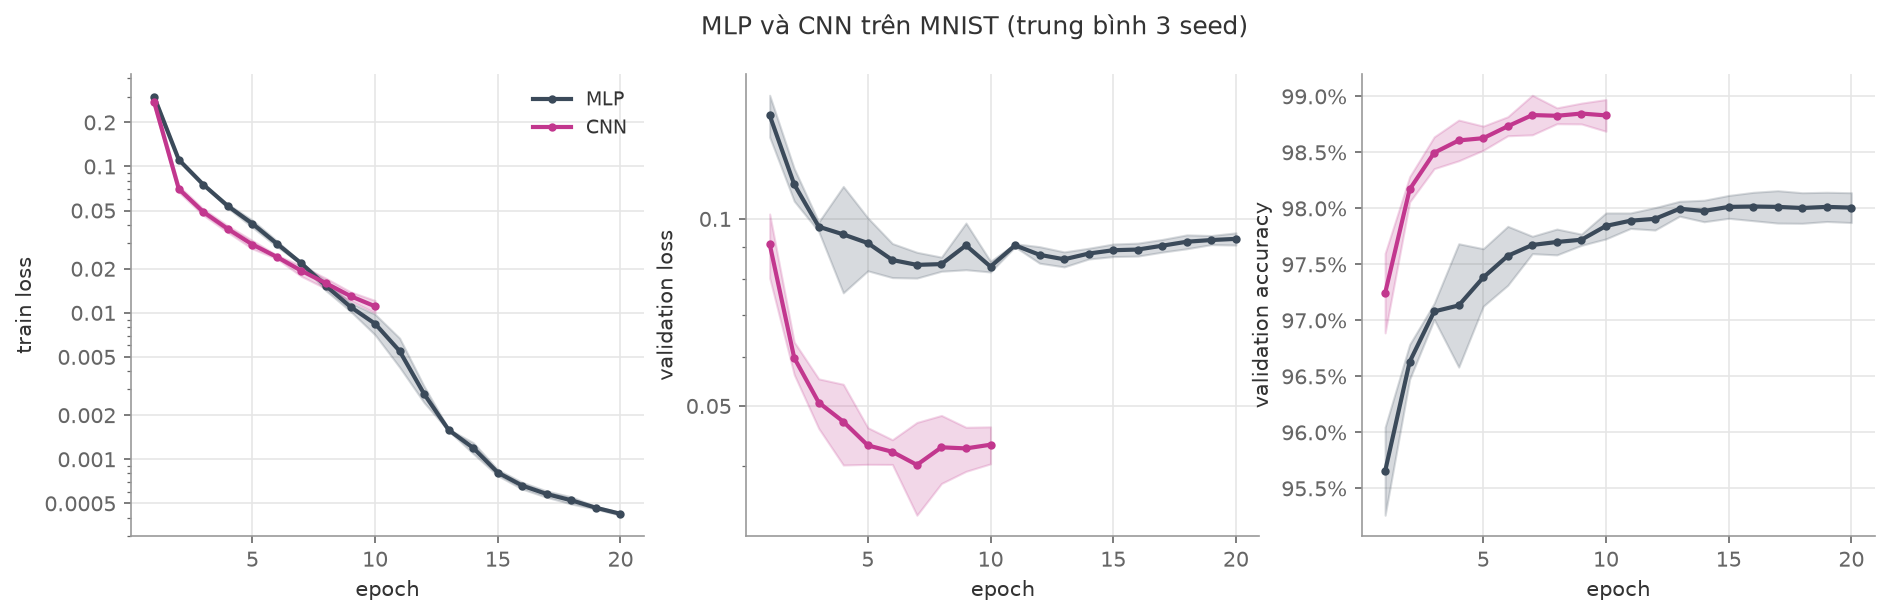

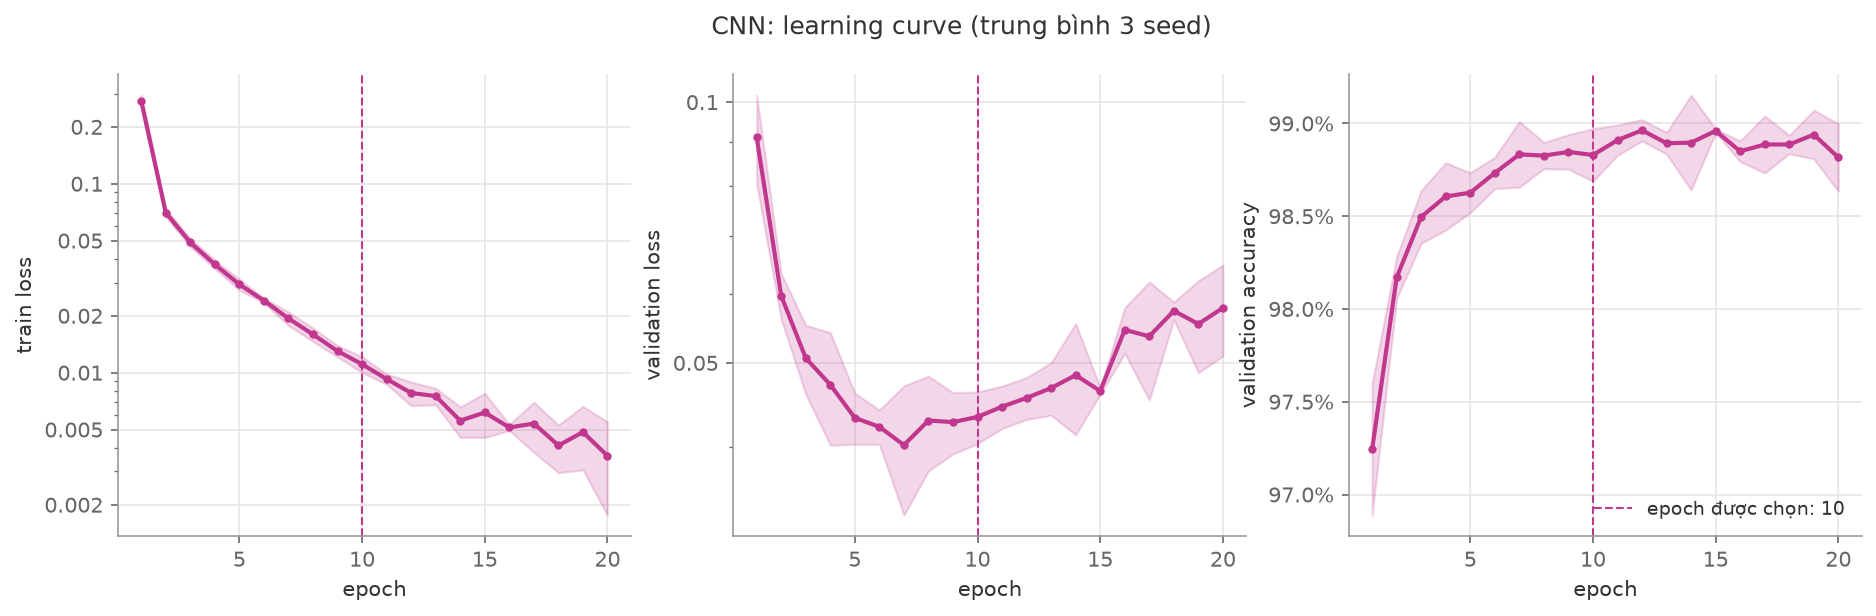

,seed,chosen_epochs,val_acc_at_chosen,val_acc_mean_before,val_acc_mean_after,val_acc_max,epoch_val_acc_max,epoch_val_loss_min
0,0,10.0,0.9894,0.9888,0.9888,0.9901,12.0000,9.0000
1,1,10.0,0.9888,0.9885,0.9888,0.9899,17.0000,7.0000
2,2,10.0,0.9867,0.9878,0.9894,0.9910,14.0000,7.0000
3,mean,10.0,0.9883,0.9883,0.9890,0.9903,14.3333,7.6667


In [46]:
display(table("cnn_vs_mlp_agg"))
figure("cnn_vs_mlp_curves")
figure("learning_curve_cnn")
display(table("learning_curve_cnn_summary"))

- CNN hơn MLP khoảng **0,77%** test (99,02% so với 98,25%), lớn hơn nhiều mức dao động theo seed; số lỗi giảm khoảng một nửa.
- Cùng số tham số nhưng CNN tốn **khoảng 11 lần phép nhân-cộng** mỗi ảnh (bộ lọc dùng lại ở mọi vị trí),
  khớp với việc mỗi epoch chậm khoảng 10 lần.
- CNN overfit ít hơn: khoảng cách train–test 0,66% so với 1,75%.
- Số epoch chọn cùng quy tắc với MLP: số epoch cố định từ đó val accuracy ngừng tăng (CNN: 10; chạy 20 epoch chỉ thêm ≤ 0,1%).

Lỗi trên test (seed 0), accuracy theo lớp, và **thí nghiệm hoán vị pixel** (một hoán vị cố định áp cho mọi ảnh):

In [47]:
display(table("cnn_vs_mlp_errors"))
display(table("cnn_vs_mlp_per_class"))
display(table("cnn_vs_mlp_permuted"))

,case,n_images
0,cả hai đúng,9794
1,chỉ MLP sai,125
2,chỉ CNN sai,37
3,cả hai sai,44


,class,n_test,mlp_acc,cnn_acc
0,0,980,0.9929,0.9969
1,1,1135,0.9930,0.9938
2,2,1032,0.9826,0.9952
3,3,1010,0.9851,0.9921
4,4,982,0.9807,0.9959
5,5,892,0.9765,0.9910
6,6,958,0.9833,0.9843
7,7,1028,0.9786,0.9912
8,8,974,0.9805,0.9908
9,9,1009,0.9762,0.9871


,model,seed,test_acc_original,test_acc_permuted,drop
0,mlp,0,0.9831,0.9829,0.0002
1,cnn,0,0.9919,0.9646,0.0273


Khi xáo pixel, MLP gần như không đổi (với MLP, thứ tự pixel không có ý nghĩa), còn CNN giảm khoảng 2,7%
và còn thấp hơn cả MLP. Đây là bằng chứng lợi thế của CNN đến từ việc dùng cấu trúc không gian của ảnh,
chứ không phải từ optimizer (MLP dùng SGD + momentum tự viết, CNN dùng Adam).

### 5.2 Data augmentation

Augment trực tuyến trên từng batch train (`src/augmentation.py`, tự cài bằng NumPy): xoay ±10°, dịch ±2 px,
nhiễu Gauss σ = 0,1 cho một nửa số ảnh; **MNIST không lật** (chữ số lật không còn là chữ số đó).
Đánh giá thêm trên ảnh test bị dịch 1–4 px và xoay 10–45° để đo độ bền.

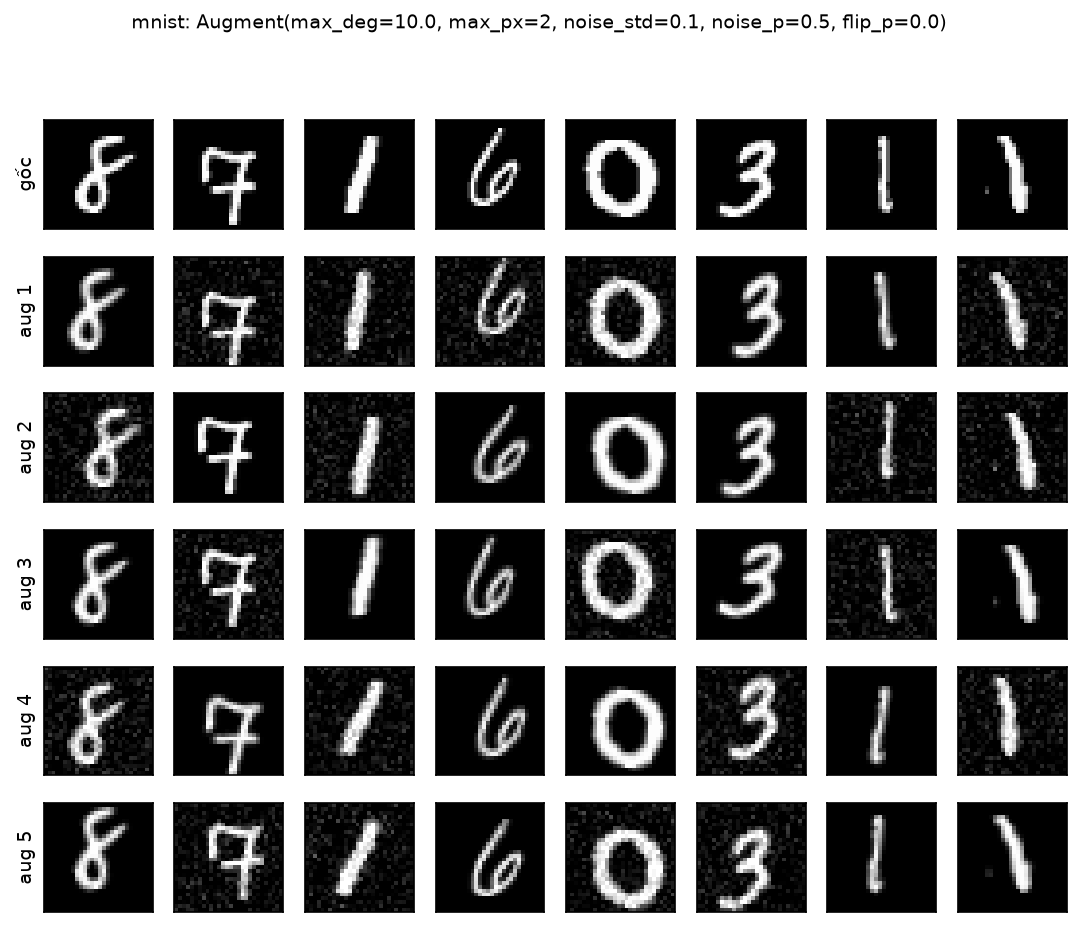

,model,augment,n_seeds,train_acc_mean,val_acc_mean,test_acc_mean,fit_time_s_mean,train_acc_std,val_acc_std,test_acc_std,fit_time_s_std
0,mlp,False,3,1.0000,0.9801,0.9825,28.4309,0.0000,0.0013,0.0010,3.5574
1,mlp,True,3,0.9876,0.9835,0.9841,127.8192,0.0003,0.0017,0.0009,6.1406
2,cnn,False,3,0.9968,0.9883,0.9902,146.9948,0.0022,0.0014,0.0018,6.0086
3,cnn,True,3,0.9929,0.9901,0.9905,217.0220,0.0012,0.0013,0.0020,1.0242


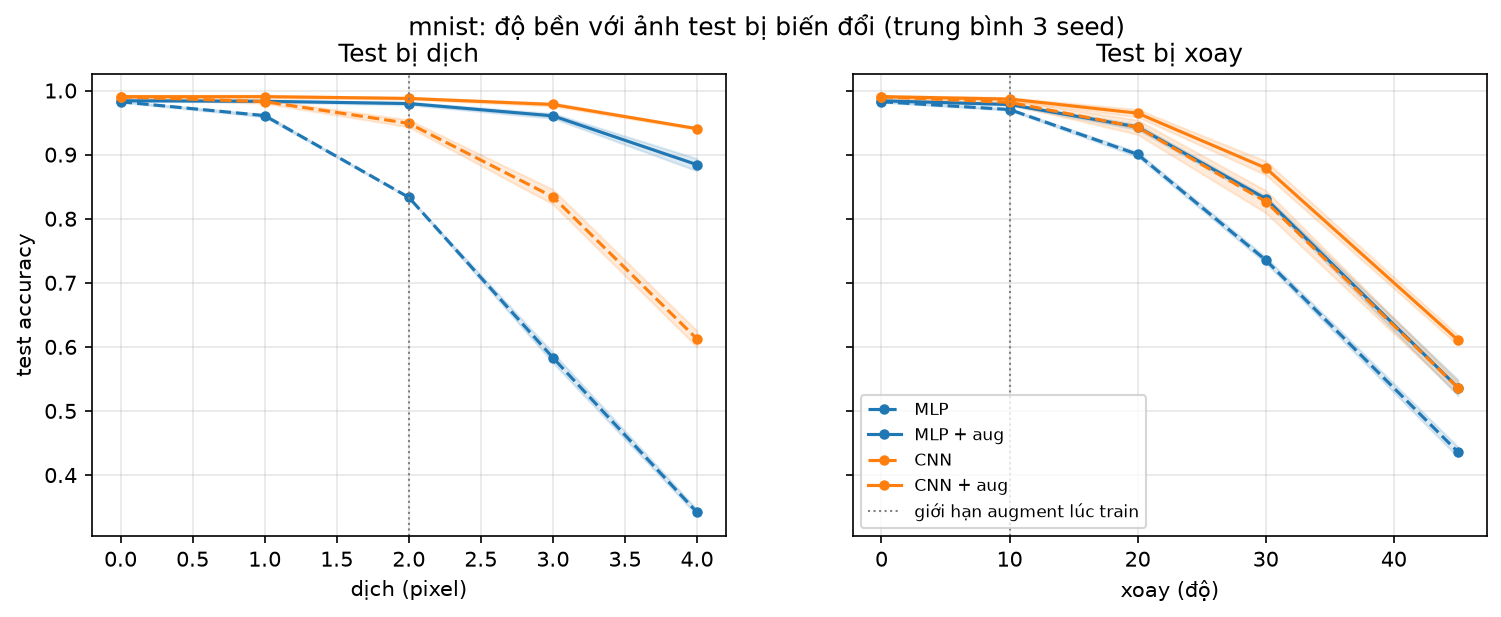

model                      cnn             mlp        
augment                  False   True    False   True 
perturbation magnitude                                
rotate       0          0.9902  0.9905  0.9825  0.9841
             10         0.9816  0.9868  0.9704  0.9782
             20         0.9428  0.9647  0.9004  0.9431
             30         0.8267  0.8791  0.7355  0.8312
             45         0.5363  0.6106  0.4361  0.5366
shift        0          0.9902  0.9905  0.9825  0.9841
             1          0.9827  0.9905  0.9609  0.9832
             2          0.9488  0.9877  0.8333  0.9797
             3          0.8341  0.9783  0.5832  0.9605
             4          0.6124  0.9405  0.3419  0.8843

In [48]:
figure("augmentation_examples", width=650)
display(table("augmentation_agg"))
figure("augmentation_robustness")
rob = table("augmentation_robustness")
if rob is not None:
    display(
        rob.pivot_table(
            index=["perturbation", "magnitude"], columns=["model", "augment"], values="test_acc"
        )
    )

- Trên test gốc, augmentation gần như không đổi accuracy (trong mức nhiễu), nhưng **giảm overfit**
  (khoảng cách train–test của MLP 1,75% → 0,35%).
- **Độ bền với dịch tăng rất mạnh**: dịch 2 px, MLP 83% → 98%, CNN 95% → 99%; kể cả dịch 3–4 px (ngoài khoảng đã augment).
- CNN không augment đã bền với dịch hơn MLP nhờ tích chập + max pooling.
- Với xoay, augment giúp ít hơn và không tổng quát được ra góc lớn (30–45°).

### 5.3 Seed ensemble và test-time augmentation (TTA)

Train 5 CNN chỉ khác seed (có và không augment), gộp bằng soft voting; đường cong lấy trung bình trên **mọi tổ hợp seed**.
TTA: trung bình xác suất trên ảnh gốc và 8 bản biến đổi (xoay ±10°, dịch ±2 px).

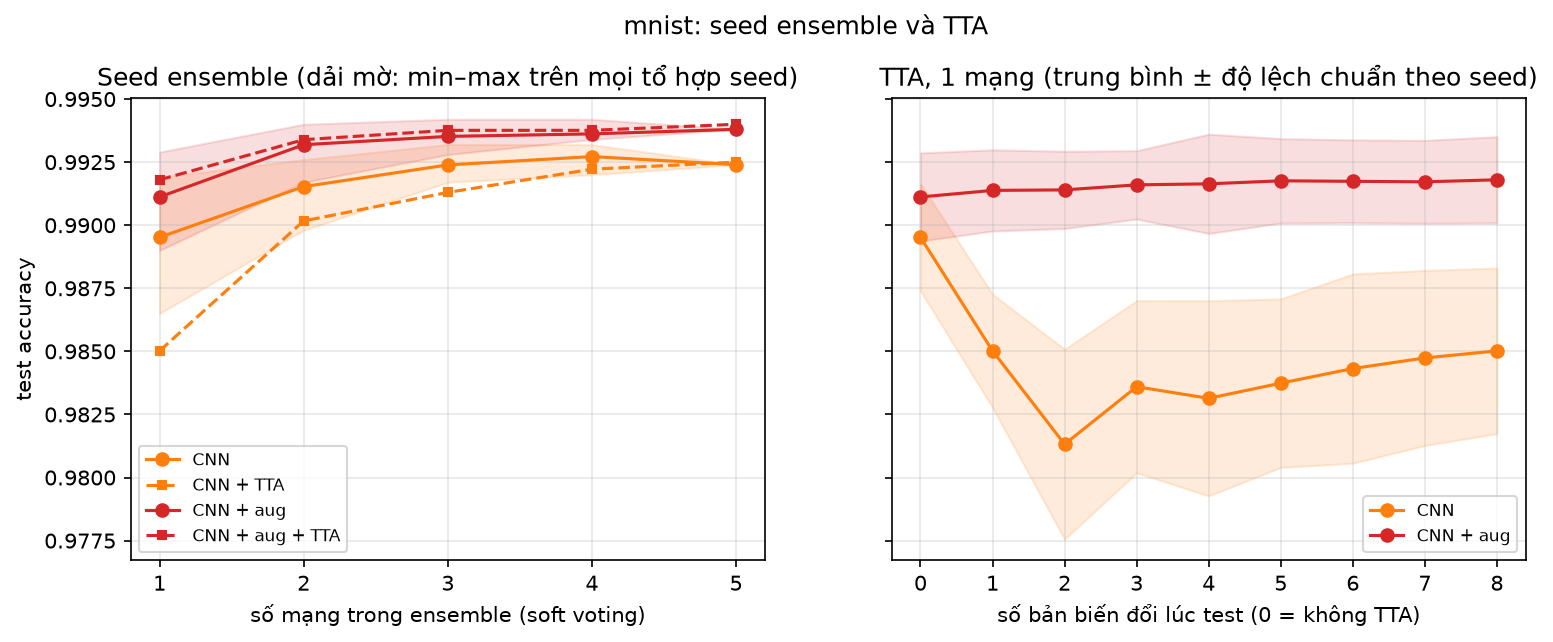

,variant,n_models,n_subsets,val_acc_mean,test_acc_mean,test_acc_min,test_acc_max,test_acc_hard_mean,test_acc_tta_mean
0,cnn,1,5,0.9876,0.9895,0.9865,0.9919,0.9895,0.9850
1,cnn,2,10,0.9901,0.9915,0.9898,0.9926,0.9915,0.9902
2,cnn,3,10,0.9908,0.9924,0.9917,0.9932,0.9923,0.9913
3,cnn,4,5,0.9914,0.9927,0.9920,0.9932,0.9928,0.9922
4,cnn,5,1,0.9914,0.9924,0.9924,0.9924,0.9926,0.9925
5,cnn_aug,1,5,0.9903,0.9911,0.9890,0.9929,0.9911,0.9918
6,cnn_aug,2,10,0.9922,0.9932,0.9917,0.9940,0.9932,0.9934
7,cnn_aug,3,10,0.9928,0.9935,0.9928,0.9942,0.9932,0.9938
8,cnn_aug,4,5,0.9932,0.9936,0.9934,0.9942,0.9937,0.9938
9,cnn_aug,5,1,0.9939,0.9938,0.9938,0.9938,0.9938,0.9940


,variant,seeds,errors_each,n_any_wrong,n_all_wrong,pct_all_wrong_of_any,n_soft_vote_wrong,n_hard_vote_wrong
0,cnn,0 1 2,81 / 95 / 117,178,30,16.8539,78,83
1,cnn_aug,0 1 2,73 / 110 / 103,177,31,17.5141,70,75


,variant,config,test_acc,test_acc_std
0,cnn,1 mạng (trung bình seed),0.9895,0.0021
1,cnn,1 mạng + TTA,0.9850,0.0033
2,cnn,5 mạng,0.9924,NaN
3,cnn,5 mạng + TTA,0.9925,NaN
4,cnn_aug,1 mạng (trung bình seed),0.9911,0.0017
5,cnn_aug,1 mạng + TTA,0.9918,0.0017
6,cnn_aug,5 mạng,0.9938,NaN
7,cnn_aug,5 mạng + TTA,0.9940,NaN


In [49]:
figure("seed_ensemble_tta")
display(table("seed_ensemble"))
display(table("seed_ensemble_coerrors"))
display(table("seed_ensemble_tta_summary"))

- **Seed ensemble** tăng khoảng +0,3%, gần bão hòa từ 3–4 mạng, khớp slide 11 B6b (3 CNN: +0,32%);
  đồng thời giảm phụ thuộc vào seed may/rủi. Ba CNN chỉ khác seed mà chỉ 17% số ảnh bị sai là sai chung,
  nên gộp lại sửa được phần lớn lỗi riêng.
- **TTA làm CNN không augment tệ đi** (ảnh biến đổi là ảnh lạ với mạng), đúng slide 14;
  với CNN có augment, TTA gần như không đổi và không giúp trên validation → mô hình cuối không dùng TTA.
- **Mô hình tốt nhất theo validation: 5 CNN + augmentation, soft voting.**

### 5.4 CNN cải tiến (ablation)

**Vì sao xây thêm một CNN.** Các thí nghiệm ở 5.1–5.3 cho thấy điểm yếu của CNN gốc: val accuracy nhảy
0,2–0,3% giữa các epoch, kết quả lệch khoảng 0,2% giữa các seed, và phải gộp 5 mạng mới ổn định.
CNN cải tiến (`ImprovedCNN`, `src/models/cnn.py`) thêm từng kỹ thuật một để xem kỹ thuật nào sửa được điểm yếu đó,
giữ số tham số xấp xỉ CNN gốc (218.586 so với 225.034). Mọi cấu hình đều có augmentation, Adam lr 1e-3, 15 epoch:

1. `v2_plain`: mỗi khối 2 lớp conv 3×3 thay vì 1, padding giữ kích thước ảnh;
2. `v2_bn`: + BatchNorm sau mỗi conv;
3. `v2_bn_drop`: + Dropout 0,3 trước lớp ra;
4. `v2_full`: + lịch learning rate cosine (giảm dần về 0 trong 15 epoch).

,config,n_seeds,n_params,train_acc_mean,val_acc_mean,test_acc_mean,fit_time_s_mean,train_acc_std,val_acc_std,test_acc_std,fit_time_s_std
0,simple_cnn_aug (mốc),3,225034.0,NaN,0.9901,0.9905,271.6581,NaN,0.0013,0.0020,14.5638
1,v2_plain,1,218490.0,0.9955,0.9914,0.9921,388.2445,NaN,NaN,NaN,NaN
2,v2_bn,1,218586.0,0.9961,0.9922,0.9940,522.2915,NaN,NaN,NaN,NaN
3,v2_bn_drop,1,218586.0,0.9953,0.9923,0.9940,556.7194,NaN,NaN,NaN,NaN
4,v2_full,3,218586.0,0.9977,0.9945,0.9955,594.2803,6.0000e-05,0.0003,0.0006,40.9155
5,v2_full (ensemble 3 seed),3,NaN,NaN,0.9949,0.9963,NaN,NaN,NaN,NaN,NaN


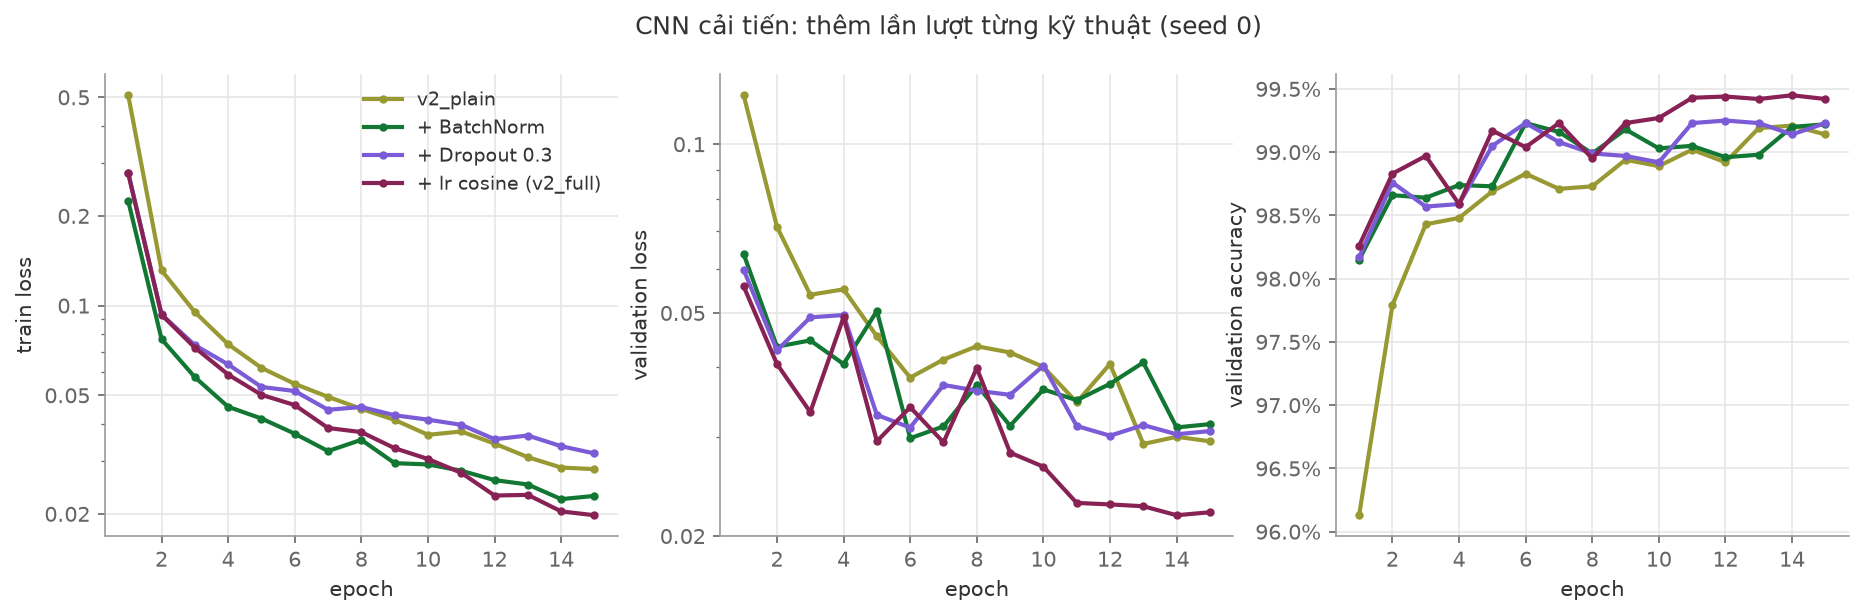

In [50]:
display(table("cnn_improved_agg"))
figure("cnn_improved_curves", width=700)

- **Ablation** (seed 0, val; cùng 15 epoch): mốc CNN gốc + aug 99,16% → 2 conv mỗi khối 99,14% → + BatchNorm 99,22%
  → + Dropout 99,23% → **+ lịch cosine 99,42%**. Chỉ bước cosine tạo khác biệt lớn hơn mức dao động theo seed;
  BatchNorm và Dropout chưa kết luận được là có giúp hay không.
- **3 seed:** `v2_full` đạt test **99,55% ± 0,06%** so với CNN gốc + aug 99,05% ± 0,20% (cùng seed), tức +0,50%,
  và **độ lệch theo seed giảm khoảng 3 lần**. Lý do: learning rate giảm về 0 nên các bước cập nhật cuối rất nhỏ,
  trọng số không còn dao động (val 5 epoch cuối gần như đứng yên), kết quả ít phụ thuộc may rủi vào epoch dừng.
- Một mạng `v2_full` đã hơn ensemble 5 CNN gốc + aug (99,38%). Ensemble 3 `v2_full` đạt **99,63%**, chỉ thêm 0,08%
  vì các mạng ít dao động nên ít lỗi riêng để sửa cho nhau.
- Lưu ý: v2 chạy 15 epoch, CNN gốc 10 epoch, nên phần chênh so với CNN gốc gồm cả số epoch.
  Trong ablation (cùng 15 epoch), thêm epoch và lớp conv mà giữ lr cố định không cải thiện; tác dụng của cosine được tách riêng.

### 5.5 Fashion-MNIST và ensemble khác loại mô hình

*(Phần của Tiên — bổ sung bảng/hình tương ứng.)* Ô dưới liệt kê các kết quả Fashion-MNIST đã có trong `results/`.

In [51]:
fashion = sorted(f for f in os.listdir(TABLES) if f.startswith("fashion_mnist_"))
print("\n".join(fashion) if fashion else "(chưa có kết quả Fashion-MNIST trong results/tables)")
for f in fashion:
    if f.endswith("_agg.csv") or f.endswith("summary.csv"):
        print(f"\n{f}")
        display(pd.read_csv(f"{TABLES}/{f}"))

(chưa có kết quả Fashion-MNIST trong results/tables)


## 6. Bảng chính, tính lại từ xác suất đã lưu

Mỗi dòng: đọc `results/probs/mnist/<mô hình>_{val,test}.npy` (lưu khi chạy script, seed 0 hoặc ensemble)
và tính accuracy so với nhãn thật. Đây là kiểm tra độc lập với các bảng CSV ở trên.

In [52]:
MODELS = [
    ("naive_bayes", "Gaussian NB"),
    ("bernoulli_naive_bayes", "Bernoulli NB"),
    ("logistic_regression", "Logistic Regression"),
    ("random_forest", "Random Forest"),
    ("mlp", "MLP"),
    ("mlp_aug", "MLP + aug"),
    ("cnn", "CNN"),
    ("cnn_aug", "CNN + aug"),
    ("cnn_tta", "CNN + TTA"),
    ("cnn_aug_tta", "CNN + aug + TTA"),
    ("cnn_ens5", "5 CNN (soft voting)"),
    ("cnn_aug_ens5", "5 CNN + aug (soft voting)"),
    ("cnn_aug_ens5_tta", "5 CNN + aug + TTA"),
]
MODELS += [  # CNN cải tiến, nếu đã chạy
    (f[: -len("_val.npy")], f[: -len("_val.npy")])
    for f in sorted(os.listdir("results/probs/mnist"))
    if f.startswith("cnn_v2") and f.endswith("_val.npy")
]
rows = []
for key, label in MODELS:
    P_val, P_test = probs(key, "val"), probs(key, "test")
    if P_val is None or P_test is None:
        continue
    rows.append(
        {
            "mô hình": label,
            "file": key,
            "val acc": acc(P_val, d["y_val"]),
            "test acc": acc(P_test, d["y_test"]),
            "số ảnh test sai": int(np.sum(P_test.argmax(axis=1) != d["y_test"])),
        }
    )
main_table = pd.DataFrame(rows)
best = main_table.loc[main_table["val acc"].idxmax()]
display(main_table.style.format({"val acc": "{:.2%}", "test acc": "{:.2%}"}))
val_best, test_best = pct(best["val acc"]), pct(best["test acc"])
print(f"Tốt nhất theo validation: {best['mô hình']} — val {val_best}, test {test_best}")

,mô hình,file,val acc,test acc,số ảnh test sai
0,Gaussian NB,naive_bayes,79.91%,81.45%,1855
1,Bernoulli NB,bernoulli_naive_bayes,83.52%,84.51%,1549
2,Logistic Regression,logistic_regression,91.75%,92.25%,775
3,Random Forest,random_forest,96.66%,96.74%,326
4,MLP,mlp,98.16%,98.31%,169
5,MLP + aug,mlp_aug,98.42%,98.51%,149
6,CNN,cnn,98.94%,99.19%,81
7,CNN + aug,cnn_aug,99.16%,99.27%,73
8,CNN + TTA,cnn_tta,98.66%,98.91%,109
9,CNN + aug + TTA,cnn_aug_tta,99.13%,99.36%,64


Tốt nhất theo validation: cnn_v2_full_ens3 — val 99.49%, test 99.63%


## 7. Kết luận, ưu điểm, hạn chế và hướng phát triển

**Kết luận**
- Bốn bộ phân lớp tự cài cho kết quả khớp với scikit-learn. Trên MNIST, thứ tự accuracy phản ánh mức độ mô hình
  dùng cấu trúc của ảnh: Naive Bayes (81–85%) < Logistic Regression (92%) < Random Forest (96,75%) < MLP (98,25%)
  < CNN (99,0%). Mỗi bước tăng accuracy tương ứng với bỏ bớt một giả định (độc lập giữa các pixel, biên tuyến tính),
  đổi lại thời gian huấn luyện dài hơn và khả năng giải thích thấp hơn.
- CNN hơn MLP ở cùng số tham số; thí nghiệm hoán vị pixel cho thấy lợi thế đến từ cấu trúc không gian của ảnh,
  không phải từ optimizer.
- Augmentation gần như không đổi accuracy trên test gốc, nhưng giảm overfit và tăng mạnh độ bền khi ảnh bị dịch
  (kể cả ngoài khoảng đã augment); với ảnh bị xoay, tác dụng nhỏ hơn.
- Seed ensemble tăng khoảng 0,3% cho CNN gốc vì các mạng khác seed sai ở những ảnh khác nhau, khớp bài giảng;
  lợi ích giảm khi các mạng thành viên đã ổn định (ensemble CNN cải tiến chỉ thêm 0,08%).
- TTA làm mô hình train không augment tệ đi (đúng bài giảng); với mô hình đã augment, TTA tăng 0,07% trên test
  nhưng không tăng trên validation, nên không dùng.
- CNN cải tiến sửa đúng điểm yếu của CNN gốc (dao động theo epoch và theo seed) nhờ lịch learning rate cosine:
  99,55% ± 0,06% với một mạng. **Mô hình cuối, chọn theo validation: ensemble 3 CNN cải tiến, test 99,63%.**
- Trên Fashion-MNIST (mục 5.5), thứ tự giữa các mô hình vẫn giữ nhưng mọi mô hình giảm 8–14 điểm do các lớp áo
  giống nhau, và augmentation thiết kế cho chữ số lại gây hại: augmentation phải chọn theo các biến đổi mà dữ liệu
  thật có, không chuyển nguyên từ bộ dữ liệu này sang bộ khác.

**Ưu điểm của cách làm**
- Phần tính toán lõi (Naive Bayes, Logistic Regression, MLP với backprop, cây quyết định, augmentation) tự cài bằng NumPy,
  có test đối chiếu với scikit-learn và test đạo hàm.
- Mọi lựa chọn (siêu tham số, số epoch, cấu hình, có dùng TTA hay không) đều dựa trên validation; test chỉ dùng cho số cuối.
- Mô hình có yếu tố ngẫu nhiên chạy nhiều seed, báo trung bình ± độ lệch chuẩn, nên phân biệt được khác biệt thật với nhiễu.
- Có thí nghiệm kiểm chứng giải thích, không chỉ báo accuracy: hoán vị pixel, ảnh test bị dịch/xoay, bảng cùng sai, ablation.
- Tái tạo được: seed cố định, xác suất lưu lại; notebook này train lại các mô hình nhanh và tính lại accuracy
  của mọi mô hình (kể cả CNN) từ xác suất đã lưu.

**Hạn chế**
- Chỉ 3 seed cho mỗi mô hình (5 seed với ensemble) và chưa làm kiểm định thống kê; với CNN gốc, chênh lệch dưới
  khoảng 0,2 điểm (ví dụ tác động của augmentation lên CNN trên MNIST) chưa đủ cơ sở để kết luận.
- Thời gian đo trên CPU, không cùng một máy cho mọi thí nghiệm và phụ thuộc tải của máy (cùng cấu hình Random Forest
  mất 13,5 s khi quét siêu tham số nhưng 90 s trong bảng chính); chỉ nên so tương đối trong cùng một bảng.
- Random Forest dùng phép tách xấp xỉ (tối đa 16 ngưỡng) và duyệt cây bằng Python, nên chậm hơn và có thể kém chính xác
  hơn một chút so với thư viện tối ưu.
- Siêu tham số được quét lần lượt từng cái, không phải grid search; cấu hình chọn trên MNIST được dùng lại nguyên vẹn cho
  Fashion-MNIST (kể cả số epoch CNN, vốn chưa đủ trên Fashion-MNIST).
- MLP (SGD + momentum, NumPy) và CNN (Adam, PyTorch) dùng optimizer và thư viện khác nhau, nên so sánh là giữa hai cấu hình
  hoàn chỉnh.
- Kiến trúc CNN gốc lấy theo bài giảng, không tối ưu. CNN cải tiến chỉ thử một hướng, ablation 1 seed mỗi bước;
  BatchNorm và Dropout chưa chứng minh được tác dụng; số epoch (15) đặt trước, khác CNN gốc (10), chưa thử lịch cosine
  với số epoch khác; chưa so với các kiến trúc hiện đại.
- Mô hình có augmentation dùng cùng số epoch với bản không augment, trong khi val accuracy của chúng vẫn còn tăng nhẹ.
  Ablation augmentation trên Fashion-MNIST chỉ chạy 1 seed và chưa tinh chỉnh độ lớn biến đổi cho bộ dữ liệu này.
- Seed ensemble, TTA và CNN cải tiến mới chạy trên MNIST.

**Hướng phát triển**
- Chọn lại siêu tham số và số epoch riêng cho Fashion-MNIST; thử augmentation phù hợp hơn như lật ngang kết hợp
  random erasing thay cho xoay/dịch.
- Áp dụng CNN cải tiến (lịch learning rate cosine) cho Fashion-MNIST, nơi khoảng cách giữa các mô hình lớn hơn.
- Chạy thêm seed cho từng bước ablation để kết luận về BatchNorm và Dropout; thử lịch cosine với số epoch khác nhau.
- Chạy thêm seed và dùng kiểm định thống kê (ví dụ McNemar) khi so sánh các mô hình có độ chính xác gần nhau.
- Kiểm tra lại augmentation và TTA trên chữ viết tay thật (ảnh từ demo), vốn khác phân phối MNIST hơn tập test.